<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X2d_vetores2d_perseguicao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio II (d): Pepé persegue Penélope no plano

## O cheiro que só diz a distância, o gradiente que diz a direção, e o filtro de partículas

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 2](X2_vetores2d.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X2_vetores2d.ipynb)) · **Anterior:** [X2c_vetores2d_edo.ipynb](X2c_vetores2d_edo.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X2c_vetores2d_edo.ipynb))

**A história, agora no plano.** Pepé e Penélope saem do corredor do notebook I(d) e entram numa **arena quadrada** de 40 m de lado. Ela foge; ele persegue, sem vê-la, guiado por sensores com ruído. As regras do mundo são as mesmas do corredor, com vetores no lugar de números.

**O que muda com a segunda dimensão.** No corredor, o olfato dizia a distância e não dizia o **lado**: duas hipóteses. No plano, um sensor que só mede a distância não diz a **direção**, e as hipóteses formam um **círculo** inteiro. O notebook I(d) terminou prometendo: "o olfato vira um gradiente, e a ambiguidade de lado vira uma ambiguidade de direção". Aqui está a promessa cumprida.

**O que este notebook mostra.**
1. Com uma **régua** de duas coordenadas, o filtro de Kalman do plano é, literalmente, dois filtros da reta, e funciona.
2. Com o **olfato** (só a intensidade do cheiro, que depende só da distância), o EKF perde Penélope em todas as simulações. E, ao contrário do corredor, o **filtro de Bayes também falha**: com um círculo de hipóteses, a informação simplesmente não está nas medidas.
3. Com o **gradiente** do cheiro (as "narinas" de Pepé comparam o cheiro dos dois lados), há direção, mas a força do gradiente não é monótona com a distância: perto e longe se confundem.
4. Com **intensidade e gradiente juntos**, o EKF acerta Penélope a menos de 10 cm, sem perder o rastro nenhuma vez.
5. O **filtro de partículas**, a versão de Monte Carlo do filtro em grade, mostra **por que** cada configuração falha ou funciona: a nuvem de partículas desenha a forma da crença.

**Roteiro**
1. O mundo: a arena, Penélope e Pepé
2. Os sensores: régua, intensidade e gradiente
3. Régua + filtro de Kalman: dois filtros da reta
4. Olfato + EKF: o círculo
5. Intensidade e gradiente: sensores que se completam
6. O filtro de partículas
7. Tudo junto
8. O que levar deste notebook
9. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido, dtype=float), np.asarray(esperado, dtype=float)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import pandas as pd
import sympy as sp
from scipy.linalg import expm
import time
N_MC = 20            # simulações de Monte Carlo por configuração (20 → ~2 min no total)
N_PART = 2000        # partículas do filtro de partículas

---

## 1. O mundo

**A arena** é o quadrado $[0,40]\times[0,40]$ m, com paredes elásticas.

**Penélope** é um ponto de massa $m=1$ kg com atrito viscoso $c=1$ N·s/m, como no corredor. As forças são as mesmas, agora vetores:
- uma **força aleatória** suave (Ornstein–Uhlenbeck), independente em cada eixo: constante de tempo de 1,5 s, desvio de 2 N;
- uma **força de fuga** de até 3 N, na direção oposta a Pepé, quando ele está a menos de 8 m;
- a força das **paredes**, molas duras que só agem se ela tentar atravessá-las.

**Pepé** é cinemático: anda na direção do ponto em que ele acha que ela está, com velocidade proporcional à distância estimada e **módulo** limitado a 2,5 m/s.

Ela começa em $(28,20)$, ele em $(12,20)$, ambos parados. A integração de Penélope usa a discretização exata do notebook II(c), com o estado $(x,y,v_x,v_y)$.

In [2]:
DT, T_FIM, L = 0.05, 60.0, 40.0
M_A, C_A = 1.0, 1.0
SIG_F, TAU_F = 2.0, 1.5
F_FUGA, R_FUGA = 3.0, 8.0
K_PAREDE = 50.0
V_MAX, GANHO = 2.5, 1.5
INICIO_A, INICIO_P = np.array([28.0, 20.0]), np.array([12.0, 20.0])

def discretiza(A, B, dt, q=None):
    """Discretização exata (notebooks I(c) e II(c))."""
    n, m = A.shape[0], B.shape[1]
    Maug = np.zeros((n + m, n + m)); Maug[:n, :n] = A; Maug[:n, n:] = B
    E = expm(Maug * dt); F, G = E[:n, :n], E[:n, n:]
    if q is None:
        return F, G
    V = np.zeros((2 * n, 2 * n)); V[:n, :n] = -A; V[:n, n:] = B @ B.T * q; V[n:, n:] = A.T
    W = expm(V * dt); Q = F @ W[:n, n:]
    return F, G, 0.5 * (Q + Q.T)

Z2, I2 = np.zeros((2, 2)), np.eye(2)
A_CV = np.block([[Z2, I2], [Z2, Z2]]); B_CV = np.vstack([Z2, I2])     # velocidade constante, estado (x, y, vx, vy)
F_PEN, G_PEN = discretiza(np.block([[Z2, I2], [Z2, -C_A / M_A * I2]]), B_CV / M_A, DT)

def forca_penelope(pa, pp, f_aleatoria):
    d = pa - pp; r = np.hypot(*d)
    fuga = F_FUGA * (d / r if r > 1e-9 else np.zeros(2)) * max(0.0, 1 - r / R_FUGA)
    parede = -K_PAREDE * np.minimum(pa, 0.0) - K_PAREDE * np.maximum(pa - L, 0.0)
    return f_aleatoria + fuga + parede

def passo_mundo(ya, pp, f_al, rng):
    f_al = f_al - f_al / TAU_F * DT + SIG_F * np.sqrt(2 * DT / TAU_F) * rng.standard_normal(2)
    return F_PEN @ ya + G_PEN @ forca_penelope(ya[:2], pp, f_al), f_al

def passo_pepe(pp, alvo):
    v = GANHO * (alvo - pp); n = np.hypot(*v)
    if n > V_MAX:
        v = v * V_MAX / n
    return np.clip(pp + v * DT, 0.0, L)

---

## 2. Os sensores

Pepé mede a cada 0,1 s (10 Hz). Seja $\mathbf d=\mathbf p_A-\mathbf p_P$ o vetor de Pepé até Penélope, $r=\|\mathbf d\|$ a distância e $\mathbf u=\mathbf d/r$ a direção.

- **Régua** (o sensor de referência): $\mathbf z=\mathbf d+\mathbf v$, com ruído independente de 0,5 m em cada eixo. Linear.
- **Intensidade do cheiro**: $z=I(r)+v$, com $I(r)=\dfrac{1}{1+(r/\ell)^2}$, $\ell=8$ m e ruído de 0,005: o olfato do notebook I(d). Depende **só da distância**.
- **Gradiente do cheiro** ("narinas"): comparando o cheiro que chega a cada narina, Pepé sente em que direção o cheiro aumenta. O gradiente de $I$ em relação à posição de Pepé aponta para Penélope:
$$\mathbf z=\nabla_{\mathbf p_P}I+\mathbf v=a(r)\,\mathbf u+\mathbf v,\qquad a(r)=-I'(r)=\frac{2r/\ell^2}{\big(1+(r/\ell)^2\big)^2},$$
com ruído de 0,002 m⁻¹ em cada eixo.

O gradiente diz a **direção** $\mathbf u$. E a **força** dele, $a(r)$? Ela é zero em cima de Penélope, cresce até um máximo e volta a cair longe dela: **não é monótona**. Cada valor de $a$ (exceto o máximo) corresponde a **duas** distâncias, uma perto e uma longe. A célula encontra o máximo com o `sympy` e, para um alvo a 11 m, a distância "gêmea" com o Newton do notebook I(b).

In [3]:
ELL, SIG_I, SIG_G, SIG_REGUA = 8.0, 0.005, 0.002, 0.5

def intensidade(r): return 1.0 / (1 + (r / ELL)**2)
def forca_grad(r):  return 2 * r / ELL**2 / (1 + (r / ELL)**2)**2          # a(r) = −I'(r)
def dforca_grad(r):
    s = 1 + (r / ELL)**2
    return 2 / ELL**2 / s**2 - 8 * r**2 / ELL**4 / s**3

rs = sp.Symbol("r", positive=True); ls = sp.Symbol("ell", positive=True)
a_s = sp.diff(-1 / (1 + (rs / ls)**2), rs)
r_max = sp.solve(sp.diff(a_s, rs), rs)
print("a(r) =", sp.simplify(a_s), ";  máximo em r =", r_max, f"= {float(r_max[0].subs(ls, ELL)):.3f} m")
confere("dforca_grad confere com o sympy", dforca_grad(5.0), float(sp.diff(a_s, rs).subs({rs: 5.0, ls: ELL})), tol=1e-15)

r_longe = 11.0; r_perto = 1.0
for _ in range(50):                                            # Newton em a(r) = a(11)
    r_perto -= (forca_grad(r_perto) - forca_grad(r_longe)) / dforca_grad(r_perto)
print(f"a(11 m) = {forca_grad(r_longe):.5f} m⁻¹ = a({r_perto:.3f} m): duas distâncias com o mesmo gradiente")
confere("a distância gêmea tem o mesmo gradiente", forca_grad(r_perto), forca_grad(r_longe), tol=1e-15)

a(r) = 2*ell**2*r/(ell**2 + r**2)**2 ;  máximo em r = [sqrt(3)*ell/3] = 4.619 m
OK   dforca_grad confere com o sympy:  diferença máxima = 0.00e+00
a(11 m) = 0.04114 m⁻¹ = a(1.398 m): duas distâncias com o mesmo gradiente
OK   a distância gêmea tem o mesmo gradiente:  diferença máxima = 0.00e+00


**O que uma medida diz.** A figura mostra, para uma única medida de cada sensor (sem ruído), em que pontos da arena Penélope **poderia** estar: a verossimilhança $p(\mathbf z\mid\mathbf p_A)$, desenhada "amolecida" (como se o ruído fosse três vezes maior), porque a verdadeira é fina demais para aparecer. Pepé está no ×; Penélope, na estrela, a uns 11 m.
- a **intensidade** diz "ela está neste círculo";
- o **gradiente** diz "ela está nesta direção, perto ou longe": duas manchas no mesmo raio;
- **os dois juntos** (o produto das verossimilhanças) dizem "ela está aqui".

As duas ambiguidades são de naturezas diferentes. O círculo é **contínuo**: há infinitas hipóteses, e nenhuma medida da intensidade feita do mesmo lugar escolhe entre elas. O par perto/longe é **discreto**: duas hipóteses, como o lado do corredor, e o movimento das duas pessoas tende a desfazer o empate.

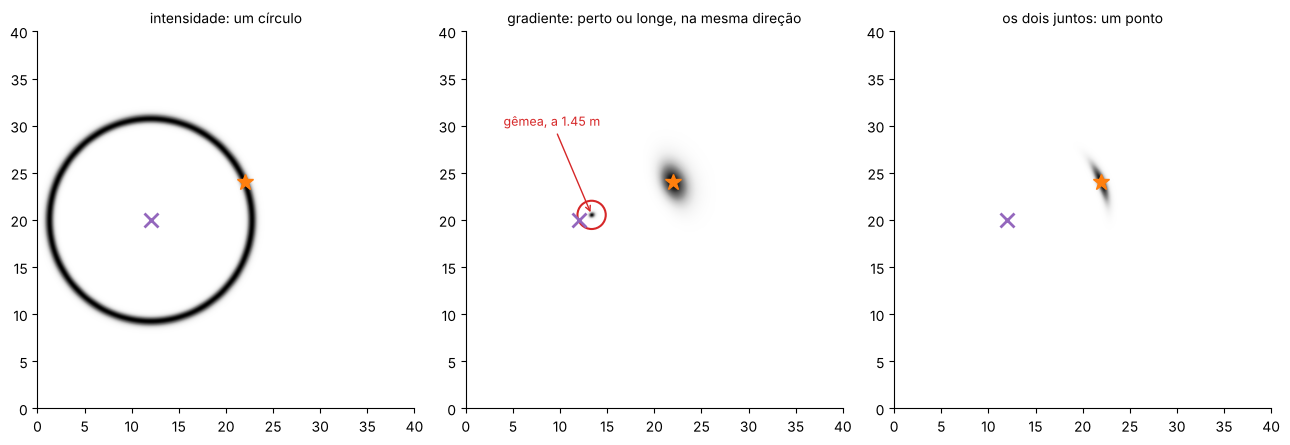

distância real: 10.77 m;  distância gêmea do gradiente: 1.45 m


In [4]:
pp_ex, pa_ex = np.array([12.0, 20.0]), np.array([22.0, 24.0])
xs = np.linspace(0, 40, 401)
GX, GY = np.meshgrid(xs, xs)
DX, DY = GX - pp_ex[0], GY - pp_ex[1]; R_ = np.hypot(DX, DY) + 1e-12
d_ex = pa_ex - pp_ex; r_ex = np.hypot(*d_ex)
z_I = intensidade(r_ex); z_g = forca_grad(r_ex) * d_ex / r_ex
lik_I = np.exp(-0.5 * (z_I - intensidade(R_))**2 / SIG_I**2)
lik_g = np.exp(-0.5 * ((z_g[0] - forca_grad(R_) * DX / R_)**2 + (z_g[1] - forca_grad(R_) * DY / R_)**2) / SIG_G**2)
fig, ax = plt.subplots(1, 3, figsize=(13, 4.4))
for a_, lik, tit in zip(ax, [lik_I, lik_g, lik_I * lik_g], ["intensidade: um círculo", "gradiente: perto ou longe, na mesma direção", "os dois juntos: um ponto"]):
    lik_vis = (lik / lik.max())**(1 / 9)                       # "amolecida" (ruído 3× maior) só para ficar visível
    a_.imshow(lik_vis, origin="lower", extent=[0, 40, 0, 40], cmap="Greys", vmin=0, vmax=1)
    a_.plot(*pp_ex, "x", color="tab:purple", ms=10, mew=2); a_.plot(*pa_ex, "*", color="tab:orange", ms=12)
    a_.set_title(tit, fontsize=10); a_.grid(False)
rg = 1.0
for _ in range(50):                                            # a distância gêmea, pelo Newton
    rg -= (forca_grad(rg) - forca_grad(r_ex)) / dforca_grad(rg)
gemea = pp_ex + rg * d_ex / r_ex
ax[1].add_patch(plt.Circle(gemea, 1.5, fill=False, color="tab:red", lw=1.5))
ax[1].annotate(f"gêmea, a {rg:.2f} m", gemea, xytext=(4, 30), color="tab:red", fontsize=9, arrowprops={"arrowstyle": "->", "color": "tab:red"})
plt.tight_layout(); plt.show()
print(f"distância real: {r_ex:.2f} m;  distância gêmea do gradiente: {rg:.2f} m")

**Os jacobianos.** O EKF precisa da derivada de cada medida em relação à posição de Penélope:
- intensidade: $\partial z/\partial\mathbf p_A=I'(r)\,\mathbf u^\top$, uma linha;
- gradiente: $\partial(a\mathbf u)/\partial\mathbf p_A=a'(r)\,\mathbf u\mathbf u^\top+\dfrac{a(r)}{r}\big(\mathbf I-\mathbf u\mathbf u^\top\big)$, uma matriz $2\times2$. O primeiro termo é a variação da força ao longo do raio; o segundo, a rotação da direção quando Penélope anda de lado.

A célula confere os dois contra diferenças finitas.

In [5]:
def h_regua(x, pp):
    H = np.zeros((2, 4)); H[0, 0] = H[1, 1] = 1.0
    return x[:2] - pp, H

def h_intensidade(x, pp):
    d = x[:2] - pp; r = max(np.hypot(*d), 1e-9)
    H = np.zeros((1, 4)); H[0, :2] = -forca_grad(r) * d / r
    return np.array([intensidade(r)]), H

def h_gradiente(x, pp):
    d = x[:2] - pp; r = max(np.hypot(*d), 1e-9); u = d / r
    a = forca_grad(r)
    H = np.zeros((2, 4)); H[:, :2] = dforca_grad(r) * np.outer(u, u) + a / r * (np.eye(2) - np.outer(u, u))
    return a * u, H

x_t, pp_t, eps = np.array([22.0, 24.0, 0.3, -0.2]), np.array([12.0, 20.0]), 1e-6
for nome, h in [("intensidade", h_intensidade), ("gradiente", h_gradiente)]:
    num = np.column_stack([(h(x_t + e, pp_t)[0] - h(x_t - e, pp_t)[0]) / (2 * eps) for e in np.eye(4) * eps])
    confere(f"jacobiano da {nome} = diferenças finitas", h(x_t, pp_t)[1], num, tol=1e-7, relativo=True)

OK   jacobiano da intensidade = diferenças finitas:  diferença relativa máxima = 1.24e-09
OK   jacobiano da gradiente = diferenças finitas:  diferença relativa máxima = 9.88e-10


---

## 3. Régua + filtro de Kalman: dois filtros da reta

**O modelo do filtro** é o de velocidade quase constante em cada eixo, com aceleração aleatória de intensidade $q=1$, discretizado exatamente (notebook II(c), seção 6). A **correção** é a de sempre, agora com medidas vetoriais:

$$\mathbf S=\mathbf H\mathbf P\mathbf H^\top+\mathbf R,\qquad\mathbf K=\mathbf P\mathbf H^\top\mathbf S^{-1},\qquad\hat{\mathbf x}\leftarrow\hat{\mathbf x}+\mathbf K(\mathbf z-h(\hat{\mathbf x})),\qquad\mathbf P\leftarrow\mathbf P-\mathbf K\mathbf S\mathbf K^\top .$$

Com a régua, o modelo e o sensor são independentes por eixo. Então o filtro do plano deve dar **exatamente** o mesmo que dois filtros da reta (um para $x$, outro para $y$) rodando lado a lado. A conferência abaixo faz isso com 200 medidas.

In [6]:
Q_INT = 1.0
F_KF, _, Q_KF = discretiza(A_CV, B_CV, DT, Q_INT)
F_KF2, _, Q_KF2 = discretiza(A_CV, B_CV, 2 * DT, Q_INT)      # um passo de medida (0,1 s)

def correcao(x, P, z, hx, H, R):
    S = H @ P @ H.T + R
    K = np.linalg.solve(S, H @ P).T                          # K = P Hᵀ S⁻¹, sem inverter S
    x = x + K @ (z - hx)
    P = P - K @ S @ K.T
    return x, 0.5 * (P + P.T)

# dois filtros da reta (domínio I) contra um filtro do plano
F1, _, Q1 = discretiza(np.array([[0, 1.0], [0, 0]]), np.array([[0], [1.0]]), 2 * DT, Q_INT)
rng_t = np.random.default_rng(0)
x2, P2 = np.array([30.0, 18.0, 0.0, 0.0]), np.diag([25.0, 25.0, 4.0, 4.0])
xr = [np.array([30.0, 0.0]), np.array([18.0, 0.0])]; Pr = [np.diag([25.0, 4.0]), np.diag([25.0, 4.0])]
for k in range(200):
    z = np.array([10.0 + np.sin(k / 20), -2.0 + np.cos(k / 30)]) + SIG_REGUA * rng_t.standard_normal(2)
    pp = np.array([12.0, 20.0])
    x2 = F_KF2 @ x2; P2 = F_KF2 @ P2 @ F_KF2.T + Q_KF2
    x2, P2 = correcao(x2, P2, z, *h_regua(x2, pp), SIG_REGUA**2 * np.eye(2))
    for e in range(2):
        xr[e] = F1 @ xr[e]; Pr[e] = F1 @ Pr[e] @ F1.T + Q1
        xr[e], Pr[e] = correcao(xr[e], Pr[e], z[e:e + 1], np.array([xr[e][0] - pp[e]]), np.array([[1.0, 0.0]]), np.array([[SIG_REGUA**2]]))
confere("filtro do plano = dois filtros da reta (estado)", x2[[0, 2, 1, 3]], np.r_[xr[0], xr[1]], tol=1e-12)
confere("filtro do plano = dois filtros da reta (covariância)", P2[np.ix_([0, 2], [0, 2])], Pr[0], tol=1e-12)

OK   filtro do plano = dois filtros da reta (estado):  diferença máxima = 0.00e+00
OK   filtro do plano = dois filtros da reta (covariância):  diferença máxima = 0.00e+00


**O simulador.** A função `simula` abaixo serve para todas as configurações do notebook: muda o filtro (EKF ou filtro de partículas, seção 6) e os sensores. Ela registra a verdade, a posição de Pepé, a estimativa, e se a verdade está dentro da **elipse de 95%** da crença ($\mathbf e^\top\mathbf P^{-1}\mathbf e<5{,}99$, o quantil de 95% da $\chi^2$ com 2 graus de liberdade).

In [7]:
F_PF, CQ_PF = F_KF2, np.linalg.cholesky(Q_KF2)          # predição das partículas a cada 0,1 s

def lik_log(s, Xp, pp, z):
    """log p(z | partícula), para cada partícula. Xp: (N, 4)."""
    D = Xp[:, :2] - pp; r = np.maximum(np.hypot(*D.T), 1e-9)
    if s == "regua":
        return -0.5 * np.sum((z - D)**2, 1) / SIG_REGUA**2
    if s == "intensidade":
        return -0.5 * (z[0] - intensidade(r))**2 / SIG_I**2
    g = (forca_grad(r) / r)[:, None] * D
    return -0.5 * np.sum((z - g)**2, 1) / SIG_G**2

BORDAS = np.arange(-100.0, 141.0, 1.0)                     # células de 1 m para achar a moda das partículas

def moda_particulas(Xp, W):
    Hh, _, _ = np.histogram2d(Xp[:, 0], Xp[:, 1], bins=[BORDAS, BORDAS], weights=W)
    if Hh.sum() < 0.5:                                     # quase todo o peso fora do histograma: usa a média
        return W @ Xp
    i, j = np.unravel_index(np.argmax(Hh), Hh.shape)
    centro = np.array([BORDAS[i] + 0.5, BORDAS[j] + 0.5])
    perto = np.hypot(*(Xp[:, :2] - centro).T) < 2.5
    return (W[perto] @ Xp[perto]) / W[perto].sum()

def simula(cfg, seed, fotos=()):
    """cfg: filtro ('ekf' ou 'pf'), sensores, tau (mirar à frente), mira ('media' ou 'moda', só no pf)."""
    rng = np.random.default_rng(seed)
    ya, pp, f_al = np.r_[INICIO_A, 0.0, 0.0], INICIO_P.copy(), np.zeros(2)
    x0 = INICIO_A + 3 * rng.standard_normal(2)
    pf = cfg["filtro"] == "pf"
    if pf:
        Xp = np.column_stack([x0 + 5 * rng.standard_normal((N_PART, 2)), 2 * rng.standard_normal((N_PART, 2))])
        W = np.full(N_PART, 1 / N_PART)
    else:
        x, P = np.r_[x0, 0.0, 0.0], np.diag([25.0, 25.0, 4.0, 4.0])
    reg = {k: [] for k in ["t", "pa", "pp", "xh", "dentro"]}; guardadas = {}
    for k in range(int(T_FIM / DT)):
        ya, f_al = passo_mundo(ya, pp, f_al, rng)
        if not pf:
            x = F_KF @ x; P = F_KF @ P @ F_KF.T + Q_KF
        if k % 2 == 1:                                            # medidas a 10 Hz
            d, LW = ya[:2] - pp, None
            if pf:
                Xp = Xp @ F_PF.T + rng.standard_normal((N_PART, 4)) @ CQ_PF.T
                LW = np.log(W)
            for s in cfg["sensores"]:
                r = np.hypot(*d)
                if s == "regua":
                    z, h, R = d + SIG_REGUA * rng.standard_normal(2), h_regua, SIG_REGUA**2 * np.eye(2)
                elif s == "intensidade":
                    z, h, R = np.array([intensidade(r) + SIG_I * rng.standard_normal()]), h_intensidade, np.array([[SIG_I**2]])
                else:
                    z, h, R = forca_grad(r) * d / max(r, 1e-9) + SIG_G * rng.standard_normal(2), h_gradiente, SIG_G**2 * np.eye(2)
                if pf:
                    LW = LW + lik_log(s, Xp, pp, z)
                else:
                    x, P = correcao(x, P, z, *h(x, pp), R)
            if pf:                                                # pesos em escala logarítmica: nada vira zero de uma vez
                W = np.exp(LW - LW.max()); W /= W.sum()
                if 1 / np.sum(W**2) < N_PART / 2:                 # reamostragem sistemática
                    u = (rng.random() + np.arange(N_PART)) / N_PART
                    Xp = Xp[np.minimum(np.searchsorted(np.cumsum(W), u), N_PART - 1)]; W = np.full(N_PART, 1 / N_PART)
        if pf:
            media = W @ Xp; Pc = (Xp - media).T @ ((Xp - media) * W[:, None])
            xh = moda_particulas(Xp, W) if cfg.get("mira", "media") == "moda" else media
            e = ya[:2] - media[:2]; Pe = Pc[:2, :2] + 1e-12 * np.eye(2)
            if round((k + 1) * DT, 2) in fotos:
                guardadas[round((k + 1) * DT, 2)] = (Xp[:, :2].copy(), ya[:2].copy(), pp.copy())
        else:
            xh, e, Pe = x, ya[:2] - x[:2], P[:2, :2]
        pp = passo_pepe(pp, xh[:2] + cfg.get("tau", 0.0) * xh[2:])
        reg["t"].append((k + 1) * DT); reg["pa"].append(ya[:2].copy()); reg["pp"].append(pp.copy())
        reg["xh"].append(xh[:2].copy()); reg["dentro"].append(e @ np.linalg.solve(Pe, e) < 5.99)
    out = {k: np.array(v) for k, v in reg.items()}
    out["fotos"] = guardadas
    return out

def metricas(h):
    e = np.hypot(*(h["pa"] - h["xh"]).T); d = np.hypot(*(h["pa"] - h["pp"]).T); k0 = int(5 / DT)
    return {"perdeu o rastro": bool((e[-int(10 / DT):] > 5).mean() > 0.9),
            "erro mediano (m)": np.median(e[k0:]),
            "tempo com erro > 5 m": np.mean(e[k0:] > 5),
            "tempo perto dela (< 1 m)": np.mean(d[k0:] < 1.0),
            "encontros": int(np.sum((d[1:] < 0.5) & (d[:-1] >= 0.5))),
            "dentro da elipse de 95%": np.mean(h["dentro"][k0:])}

def monte_carlo(configs, n=N_MC):
    tab = {}
    for nome, cfg in configs.items():
        t0 = time.time()
        d = pd.DataFrame([metricas(simula(cfg, 100 + r)) for r in range(n)])
        tab[nome] = {"perdeu o rastro": f"{d['perdeu o rastro'].sum()} de {n}",
                     **{k: d[k].median() for k in d.columns if k != "perdeu o rastro"},
                     "segundos": time.time() - t0}
    return pd.DataFrame(tab).T

def desenha(h, titulo, ax):
    ax.plot(*h["pa"].T, "k", lw=1.2, label="Penélope (verdade)")
    ax.plot(*h["pp"].T, color="tab:purple", lw=1.0, label="Pepé")
    ax.plot(*h["xh"].T, color="tab:orange", lw=0.8, alpha=.8, label="estimativa de Pepé")
    ax.plot(*h["pa"][0], "ko", ms=6); ax.plot(*h["pp"][0], "o", color="tab:purple", ms=6)
    ax.add_patch(plt.Rectangle((0, 0), L, L, fill=False, lw=2))
    ax.set_xlim(-8, 48); ax.set_ylim(-8, 48); ax.set_aspect("equal"); ax.set_title(titulo, fontsize=10)

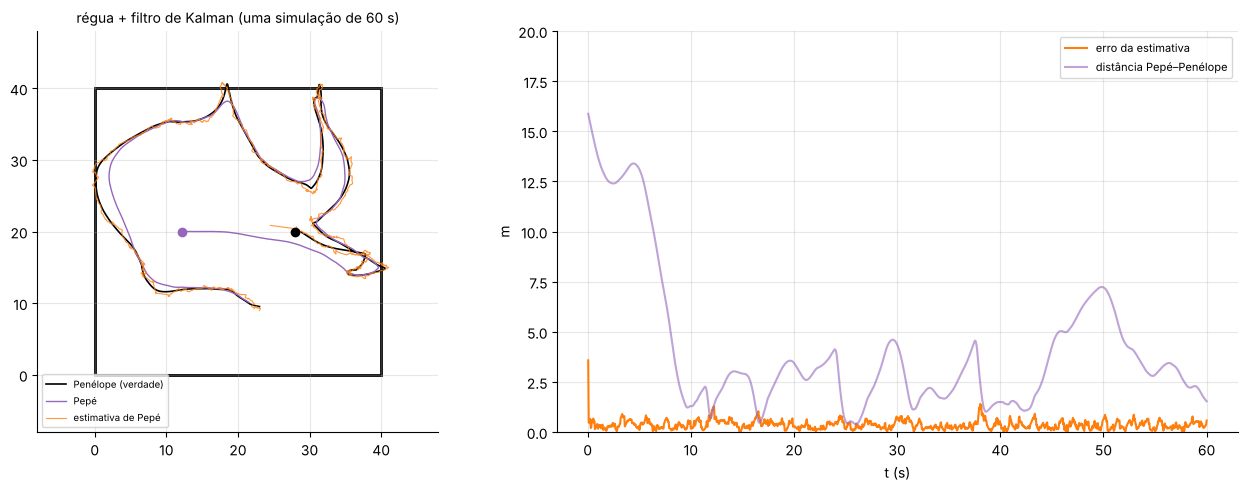

,perdeu o rastro,erro mediano (m),tempo com erro > 5 m,tempo perto dela (< 1 m),encontros,dentro da elipse de 95%,segundos
régua + KF,0 de 20,0.367744,0.0,0.073636,2.0,0.92,1.557283
"régua + KF, mira à frente (τ = 0,8 s)",0 de 20,0.374228,0.0,0.166818,4.0,0.900909,1.589042


In [8]:
h = simula({"filtro": "ekf", "sensores": ["regua"]}, 100)
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.4]})
desenha(h, "régua + filtro de Kalman (uma simulação de 60 s)", ax[0]); ax[0].legend(fontsize=7, loc="lower left")
ax[1].plot(h["t"], np.hypot(*(h["pa"] - h["xh"]).T), color="tab:orange", label="erro da estimativa")
ax[1].plot(h["t"], np.hypot(*(h["pa"] - h["pp"]).T), color="tab:purple", alpha=.6, label="distância Pepé–Penélope")
ax[1].set_xlabel("t (s)"); ax[1].set_ylabel("m"); ax[1].legend(fontsize=8); ax[1].set_ylim(0, 20)
plt.tight_layout(); plt.show()

tab_regua = monte_carlo({"régua + KF": {"filtro": "ekf", "sensores": ["regua"]},
                         "régua + KF, mira à frente (τ = 0,8 s)": {"filtro": "ekf", "sensores": ["regua"], "tau": 0.8}})
tab_regua.round(3)

**Leitura.** Como no corredor, a régua nunca perde Penélope, e o erro mediano fica abaixo do ruído da própria régua. A elipse de 95% contém a verdade em pouco mais de 90% do tempo: o filtro é levemente otimista, porque o modelo de velocidade quase constante não sabe da fuga nem das paredes. Mirar onde ela estará daqui a 0,8 s mais que dobra o tempo que Pepé passa perto dela.

---

## 4. Olfato + EKF: o círculo

Agora Pepé só tem a **intensidade** do cheiro. O EKF lineariza $I(r)$ em torno da estimativa: a linha $\mathbf H=I'(\hat r)\,\hat{\mathbf u}^\top$ só tem componente na direção **radial**, a que liga Pepé à estimativa. Cada correção move a estimativa para perto ou para longe de Pepé, nunca de lado. A informação sobre a direção vem só do *prior* e do movimento; se a estimativa começa a escorregar ao longo do círculo, nada a traz de volta.

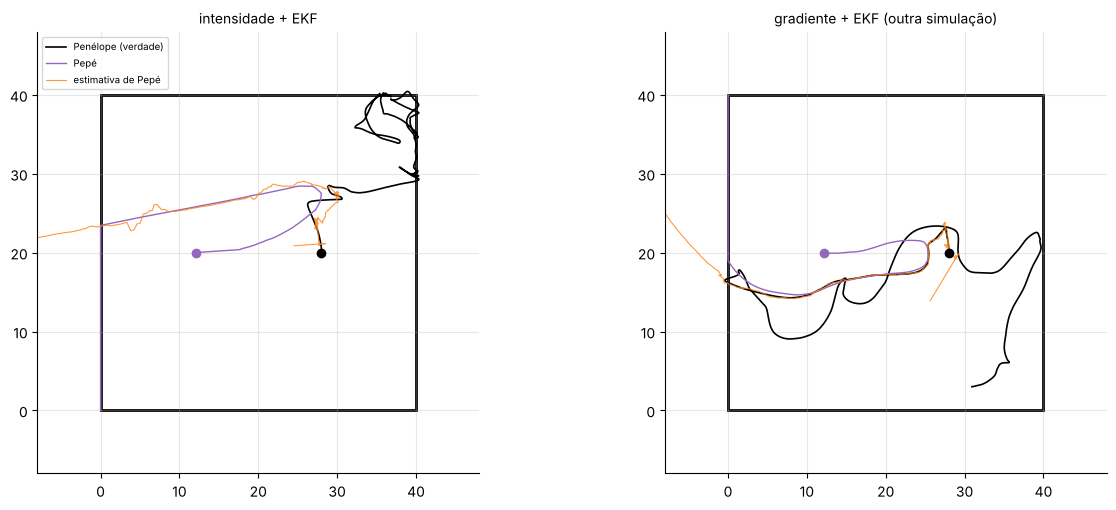

,perdeu o rastro,erro mediano (m),tempo com erro > 5 m,tempo perto dela (< 1 m),encontros,dentro da elipse de 95%,segundos
intensidade + EKF,20 de 20,51.113054,1.0,0.0,0.0,0.0,1.661192
gradiente + EKF,12 de 20,0.312503,0.293636,0.054091,1.0,0.571818,2.059294


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
desenha(simula({"filtro": "ekf", "sensores": ["intensidade"]}, 100), "intensidade + EKF", ax[0])
desenha(simula({"filtro": "ekf", "sensores": ["gradiente"]}, 101), "gradiente + EKF (outra simulação)", ax[1])
ax[0].legend(fontsize=7, loc="upper left"); plt.tight_layout(); plt.show()

tab_ekf = monte_carlo({"intensidade + EKF": {"filtro": "ekf", "sensores": ["intensidade"]},
                       "gradiente + EKF": {"filtro": "ekf", "sensores": ["gradiente"]}})
tab_ekf.round(3)

**Leitura.**
- Com a **intensidade**, o EKF perde Penélope em todas as simulações. A figura da esquerda mostra o padrão: a estimativa escorrega para longe, sai da arena (o filtro não sabe que há paredes), e Pepé fica preso contra a parede, perseguindo um ponto do lado de fora. A elipse de 95% quase nunca contém a verdade: o filtro está confiante numa hipótese que não é a dela.
- Com o **gradiente** sozinho, o EKF vai melhor, mas perde o rastro em mais da metade das simulações. Na figura da direita, a estimativa acompanha Penélope por 16 s e então dispara para fora da arena. O registro da simulação mostra o mecanismo: Penélope se aproxima de Pepé, de 5,7 m para 0,3 m em dois segundos, atravessando a distância do máximo de $a(r)$ (4,6 m); o gradiente sobe e depois desce, e o EKF interpreta a descida como se ela estivesse se **afastando**, no outro ramo da curva. Quando ela está a 0,3 m, a estimativa está a 16 m. É a distância gêmea da seção 2, percorrida continuamente.

Os dois sensores falham por razões **complementares**: um não sabe a direção, o outro confunde perto com longe.

---

## 5. Intensidade e gradiente: sensores que se completam

A figura da seção 2 já disse a resposta: o produto das duas verossimilhanças é um ponto só. Com os dois sensores, o EKF recebe, a cada 0,1 s, três números: a intensidade (que fixa a distância) e o gradiente (que fixa a direção).

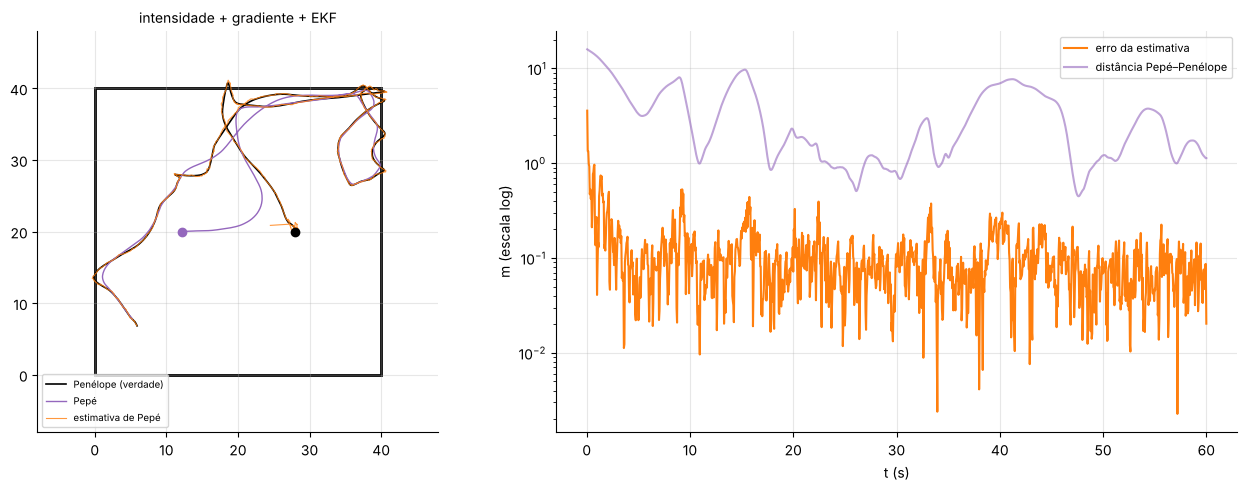

Pepé entre  0.0 e  0.5 m dela: erro mediano   7.6 cm  ( 2.5% do tempo)
Pepé entre  0.5 e  2.0 m dela: erro mediano   7.3 cm  (32.6% do tempo)
Pepé entre  2.0 e  4.0 m dela: erro mediano   7.6 cm  (28.6% do tempo)
Pepé entre  4.0 e  8.0 m dela: erro mediano   9.4 cm  (30.5% do tempo)
Pepé entre  8.0 e 15.0 m dela: erro mediano  17.7 cm  ( 5.7% do tempo)


,perdeu o rastro,erro mediano (m),tempo com erro > 5 m,tempo perto dela (< 1 m),encontros,dentro da elipse de 95%,segundos
intensidade + gradiente + EKF,0 de 20,0.082109,0.0,0.102727,2.0,0.934091,2.582181
"intensidade + gradiente + EKF, mira à frente",0 de 20,0.081951,0.0,0.354545,5.0,0.905909,2.470515


In [10]:
h = simula({"filtro": "ekf", "sensores": ["intensidade", "gradiente"]}, 100)
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.4]})
desenha(h, "intensidade + gradiente + EKF", ax[0]); ax[0].legend(fontsize=7, loc="lower left")
ax[1].semilogy(h["t"], np.hypot(*(h["pa"] - h["xh"]).T) + 1e-4, color="tab:orange", label="erro da estimativa")
ax[1].semilogy(h["t"], np.hypot(*(h["pa"] - h["pp"]).T), color="tab:purple", alpha=.6, label="distância Pepé–Penélope")
ax[1].set_xlabel("t (s)"); ax[1].set_ylabel("m (escala log)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

tab_ambos = monte_carlo({"intensidade + gradiente + EKF": {"filtro": "ekf", "sensores": ["intensidade", "gradiente"]},
                         "intensidade + gradiente + EKF, mira à frente": {"filtro": "ekf", "sensores": ["intensidade", "gradiente"], "tau": 0.8}})

# o erro depende da distância? (as mesmas 20 simulações, sem mira à frente)
E_, D_ = [], []
for r_ in range(N_MC):
    hh = simula({"filtro": "ekf", "sensores": ["intensidade", "gradiente"]}, 100 + r_)
    E_.append(np.hypot(*(hh["pa"] - hh["xh"]).T)[100:]); D_.append(np.hypot(*(hh["pa"] - hh["pp"]).T)[100:])
E_, D_ = np.concatenate(E_), np.concatenate(D_)
for a_, b_ in [(0, 0.5), (0.5, 2), (2, 4), (4, 8), (8, 15)]:
    m_ = (D_ >= a_) & (D_ < b_)
    print(f"Pepé entre {a_:4.1f} e {b_:4.1f} m dela: erro mediano {100 * np.median(E_[m_]):5.1f} cm  ({100 * m_.mean():4.1f}% do tempo)")
tab_ambos.round(3)

**Leitura.** Com os dois sensores, o EKF nunca perde Penélope, e o erro mediano cai para menos de 10 cm, pouco mais de um quinto do erro da régua: os dois sensores do cheiro, juntos, são muito mais precisos que a régua de 0,5 m. Mirando à frente, Pepé passa mais de um terço do tempo a menos de um metro dela.

Repare no gráfico da direita: o erro é maior quando Pepé está **longe** dela. As linhas impressas acima da tabela confirmam isso nas 20 simulações: o erro mediano é de uns 7 cm com Pepé a menos de 4 m e passa de 17 cm com ele entre 8 e 15 m. Longe, a intensidade e o gradiente variam pouco com a posição, e cada medida informa menos. E o ponto cego do corredor, em $r=0$, onde $I'(0)=0$ e $a(0)=0$? No plano, Pepé quase nunca passa **exatamente** por cima dela, e os momentos em que ele está a menos de meio metro não pioram o erro de modo visível.

---

## 6. O filtro de partículas

No corredor, o filtro de Bayes numa grade salvou o olfato, porque carregava as duas hipóteses (os dois lados). No plano, a grade teria de cobrir posições **e** velocidades em duas dimensões: com a resolução do corredor, uns $10^9$ pontos. O **filtro de partículas** é a saída: em vez de uma grade fixa, uma **nuvem** de $N$ pontos (as partículas) que vai para onde a crença está.

**Um passo do filtro de partículas, a cada medida:**
1. **predição:** cada partícula anda com o modelo de movimento, **com o ruído sorteado** (a mesma aceleração aleatória do Kalman, agora como sorteio): $\mathbf x_i\leftarrow\mathbf F\mathbf x_i+\mathbf w_i$, com $\mathbf w_i\sim\mathcal N(\mathbf 0,\mathbf Q)$;
2. **correção:** cada partícula recebe um **peso** proporcional à verossimilhança da medida, $w_i\propto w_i\,p(\mathbf z\mid\mathbf x_i)$. Não há linearização nem jacobiano: só é preciso **avaliar** o modelo do sensor;
3. **reamostragem:** quando poucas partículas concentram quase todo o peso (o "tamanho efetivo" $1/\sum w_i^2$ cai abaixo de $N/2$), sorteiam-se $N$ partículas novas entre as velhas, com probabilidade proporcional ao peso. As de peso alto se multiplicam, as de peso baixo desaparecem.

É um Monte Carlo que se corrige com as medidas: a nuvem da banana do notebook II(c), mais a regra de Bayes. Dois cuidados de implementação, ambos na função `simula`:
- os pesos são guardados em **escala logarítmica**. Com a intensidade, de ruído 0,005, uma partícula a 1 m da verdade tem verossimilhança da ordem de $e^{-80}$; multiplicando várias medidas, os pesos passam do menor `float` e viram zero (é o subtransbordamento do notebook II(a));
- a estimativa usada para mirar pode ser a **média** das partículas ou a **moda** (a célula de 1 m com mais peso, refinada pela média das partículas próximas), como no corredor.

**A conferência de sempre:** com um sensor linear (a régua), a crença é gaussiana e o filtro de partículas deve concordar com o Kalman, a menos do erro de Monte Carlo. A célula usa 20 000 partículas, para que o erro de Monte Carlo fique pequeno.

In [11]:
rng_t = np.random.default_rng(1)
n_teste = 20000
pp, pa_fixa = np.array([12.0, 20.0]), np.array([31.0, 22.0])
x, P = np.array([30.0, 20.0, 0.0, 0.0]), np.diag([25.0, 25.0, 4.0, 4.0])
Xp = rng_t.multivariate_normal(x, P, n_teste); W = np.full(n_teste, 1 / n_teste)
for k in range(30):
    x = F_KF2 @ x; P = F_KF2 @ P @ F_KF2.T + Q_KF2
    Xp = Xp @ F_KF2.T + rng_t.standard_normal((n_teste, 4)) @ CQ_PF.T
    z = pa_fixa - pp + SIG_REGUA * rng_t.standard_normal(2)
    x, P = correcao(x, P, z, *h_regua(x, pp), SIG_REGUA**2 * np.eye(2))
    LW = np.log(W) + lik_log("regua", Xp, pp, z); W = np.exp(LW - LW.max()); W /= W.sum()
    if 1 / np.sum(W**2) < n_teste / 2:
        u = (rng_t.random() + np.arange(n_teste)) / n_teste
        Xp = Xp[np.minimum(np.searchsorted(np.cumsum(W), u), n_teste - 1)]; W = np.full(n_teste, 1 / n_teste)
media = W @ Xp; Pc = (Xp - media).T @ ((Xp - media) * W[:, None])
print(f"KF:        posição {x[:2].round(3)}, desvios {np.sqrt(np.diag(P)[:2]).round(3)}")
print(f"partículas: posição {media[:2].round(3)}, desvios {np.sqrt(np.diag(Pc)[:2]).round(3)}")
confere("partículas = KF (média da posição)", media[:2], x[:2], tol=0.03)
confere("partículas = KF (desvio da posição)", np.sqrt(np.diag(Pc)[:2]), np.sqrt(np.diag(P)[:2]), tol=0.1, relativo=True)

KF:        posição [31.448 21.848], desvios [0.274 0.274]
partículas: posição [31.449 21.851], desvios [0.271 0.272]
OK   partículas = KF (média da posição):  diferença máxima = 3.61e-03
OK   partículas = KF (desvio da posição):  diferença relativa máxima = 8.06e-03


**A forma da crença.** A célula abaixo roda o filtro de partículas com cada um dos três sensores do cheiro, na mesma simulação, e fotografa a nuvem aos 3 s e aos 22 s. Os pontos pretos são as partículas; a estrela, Penélope; o ×, Pepé; o quadrado, a arena. Cada quadro mostra uma janela de 44 m centrada em Pepé.

intensidade              t =    3 s: Pepé a  8.13 m dela;  partículas a  8.12 m de Pepé (mediana) e a  1.64 m dela
intensidade              t =   22 s: Pepé a 19.34 m dela;  partículas a 19.35 m de Pepé (mediana) e a 35.25 m dela


gradiente                t =    3 s: Pepé a  9.80 m dela;  partículas a  9.64 m de Pepé (mediana) e a  0.35 m dela
gradiente                t =   22 s: Pepé a  2.54 m dela;  partículas a  7.18 m de Pepé (mediana) e a  4.64 m dela


intensidade + gradiente  t =    3 s: Pepé a  8.80 m dela;  partículas a  8.79 m de Pepé (mediana) e a  0.18 m dela
intensidade + gradiente  t =   22 s: Pepé a  8.41 m dela;  partículas a  8.48 m de Pepé (mediana) e a  0.49 m dela


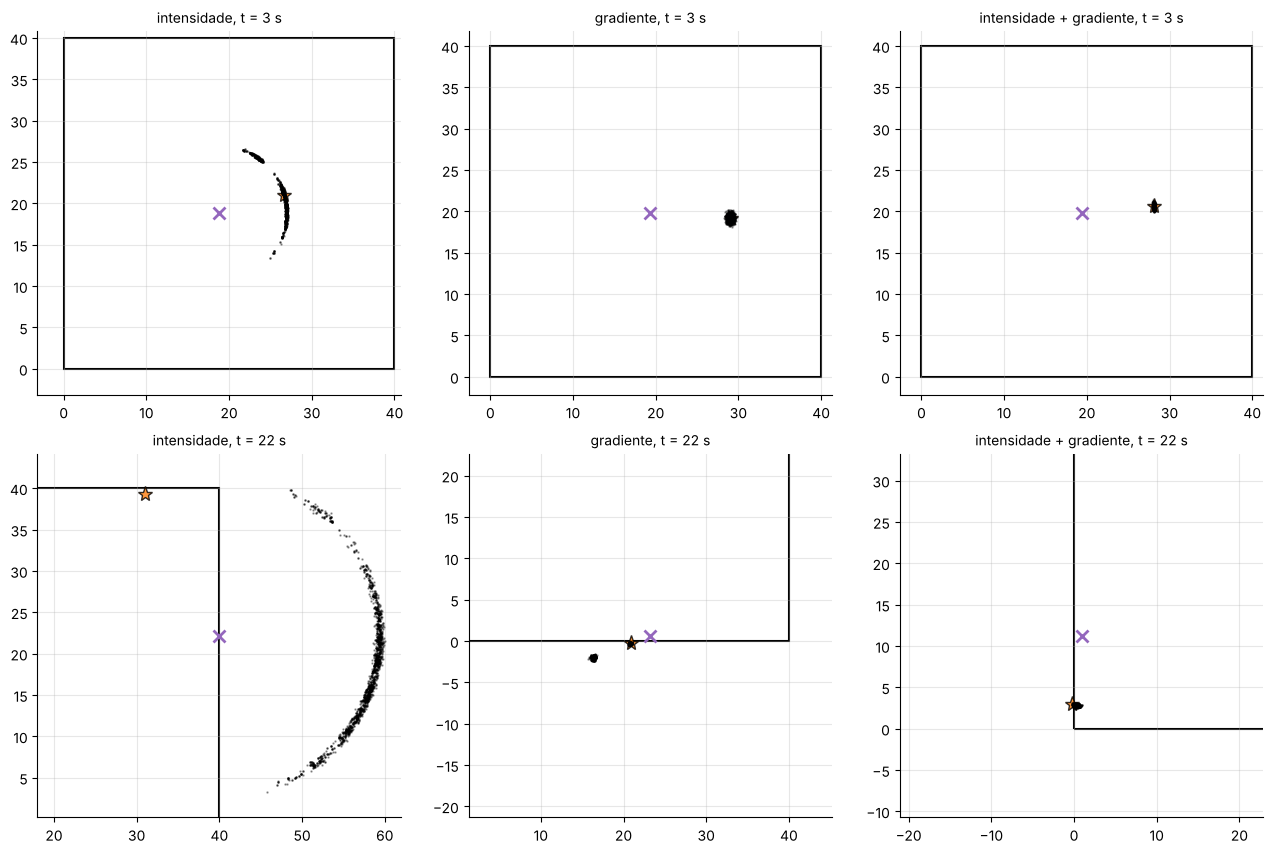

In [12]:
fotos = (3.0, 22.0)
configs_pf = {"intensidade": ["intensidade"], "gradiente": ["gradiente"], "intensidade + gradiente": ["intensidade", "gradiente"]}
fig, axs = plt.subplots(2, 3, figsize=(13, 8.6))
for j, (nome, sens) in enumerate(configs_pf.items()):
    hh = simula({"filtro": "pf", "sensores": sens, "mira": "moda"}, 100, fotos=fotos)
    for i, tf in enumerate(fotos):
        Xf, paf, ppf = hh["fotos"][tf]; a_ = axs[i, j]
        a_.plot(*paf, "*", color="tab:orange", ms=11, mec="k", alpha=.8); a_.plot(*ppf, "x", color="tab:purple", ms=9, mew=2)
        a_.plot(*Xf.T, ".", ms=1.5, color="k", alpha=.35, zorder=3)
        a_.add_patch(plt.Rectangle((0, 0), L, L, fill=False, lw=1.5))
        a_.set_xlim(ppf[0] - 22, ppf[0] + 22); a_.set_ylim(ppf[1] - 22, ppf[1] + 22); a_.set_aspect("equal")
        a_.set_title(f"{nome}, t = {tf:.0f} s", fontsize=10)
        print(f"{nome:24s} t = {tf:4.0f} s: Pepé a {np.hypot(*(paf - ppf)):5.2f} m dela;  partículas a {np.median(np.hypot(*(Xf - ppf).T)):5.2f} m de Pepé"
              f" (mediana) e a {np.median(np.hypot(*(Xf - paf).T)):5.2f} m dela")
plt.tight_layout(); plt.show()

**Leitura da figura** (os números impressos acima da figura dão as distâncias).
- **Intensidade:** a nuvem é um **arco** em volta de Pepé, com raio igual à distância medida (as partículas estão, em mediana, a 8,1 m dele quando ele está a 8,1 m dela). Aos 3 s, o arco ainda passa por Penélope; aos 22 s, o arco tem o raio certo (19,3 m) e está **do lado errado**, inteiramente fora da arena, a 35 m dela. O filtro de partículas não erra a conta: a crença é um pedaço de círculo, e as medidas de intensidade, todas feitas de perto do mesmo lugar, não dizem qual pedaço. Sem saber que há paredes, nada impede a nuvem de ir para fora.
- **Gradiente:** aos 3 s, a nuvem está em cima de Penélope. Aos 22 s, Pepé está a 2,5 m dela, e a nuvem inteira está a 7,2 m dele, na mesma direção: é a **distância gêmea**, $a(2{,}5)pprox a(7{,}2)$. Neste momento, o filtro de partículas escolheu o ramo errado, como o EKF.
- **Os dois:** uma nuvem pequena, a menos de meio metro de Penélope nas duas fotos.

Agora o Monte Carlo. Para o gradiente e para a intensidade sozinhos, Pepé mira na **moda** (o pedaço mais pesado da nuvem); com os dois sensores, a nuvem é única e ele mira na **média**.

In [13]:
tab_pf = monte_carlo({"intensidade + partículas (moda)": {"filtro": "pf", "sensores": ["intensidade"], "mira": "moda"},
                      "gradiente + partículas (moda)": {"filtro": "pf", "sensores": ["gradiente"], "mira": "moda"},
                      "intensidade + gradiente + partículas": {"filtro": "pf", "sensores": ["intensidade", "gradiente"]}})
tab_pf.round(3)

,perdeu o rastro,erro mediano (m),tempo com erro > 5 m,tempo perto dela (< 1 m),encontros,dentro da elipse de 95%,segundos
intensidade + partículas (moda),8 de 20,10.408414,0.572273,0.0,0.0,0.401818,14.313097
gradiente + partículas (moda),9 de 20,0.229729,0.093182,0.055909,1.5,0.666818,14.089694
intensidade + gradiente + partículas,0 de 20,0.129349,0.0,0.08,2.0,0.593636,8.120058


**Leitura.**
- **Intensidade:** o filtro de partículas perde Penélope em 8 de 20 simulações, e na mediana passa mais da metade do tempo com erro acima de 5 m. É melhor que o EKF (que perdia em todas), mas não resolve: a informação sobre a direção não está nas medidas.
- **Gradiente:** perde em 9 de 20 (o EKF perdia em 12), e o tempo mediano com erro acima de 5 m cai de 29% para 9%. A ambiguidade perto/longe é **discreta**, como o lado do corredor, e uma nuvem de partículas pode carregar as duas hipóteses; mas, com um sensor preciso, as partículas da hipótese que está momentaneamente em desvantagem morrem na reamostragem, e a hipótese desaparece antes de ser necessária. Num teste feito na preparação deste notebook, com 10 000 partículas, as perdas caíram para 6 de 20 e o tempo mediano com erro acima de 5 m caiu para menos de 1%: mais partículas, menos empobrecimento (exercício 3).
- **Intensidade e gradiente:** nunca perde, como o EKF, com erro mediano de uns 13 cm, um pouco **pior** que o do EKF (8 cm), e custando de três a quatro vezes mais tempo. A elipse de 95% das partículas contém a verdade só em cerca de 60% do tempo: a nuvem é estreita demais, outro sintoma do empobrecimento.

---

## 7. Tudo junto

In [14]:
tab = pd.concat([tab_regua, tab_ekf, tab_ambos, tab_pf])
tab.round(3)

,perdeu o rastro,erro mediano (m),tempo com erro > 5 m,tempo perto dela (< 1 m),encontros,dentro da elipse de 95%,segundos
régua + KF,0 de 20,0.367744,0.0,0.073636,2.0,0.92,1.557283
"régua + KF, mira à frente (τ = 0,8 s)",0 de 20,0.374228,0.0,0.166818,4.0,0.900909,1.589042
intensidade + EKF,20 de 20,51.113054,1.0,0.0,0.0,0.0,1.661192
gradiente + EKF,12 de 20,0.312503,0.293636,0.054091,1.0,0.571818,2.059294
intensidade + gradiente + EKF,0 de 20,0.082109,0.0,0.102727,2.0,0.934091,2.582181
"intensidade + gradiente + EKF, mira à frente",0 de 20,0.081951,0.0,0.354545,5.0,0.905909,2.470515
intensidade + partículas (moda),8 de 20,10.408414,0.572273,0.0,0.0,0.401818,14.313097
gradiente + partículas (moda),9 de 20,0.229729,0.093182,0.055909,1.5,0.666818,14.089694
intensidade + gradiente + partículas,0 de 20,0.129349,0.0,0.08,2.0,0.593636,8.120058


**Leitura.** A tabela conta a história do notebook em uma coluna, a primeira:
- a **régua** e a **intensidade com gradiente** nunca perdem Penélope, com qualquer filtro;
- a **intensidade sozinha** perde sempre com o EKF e com frequência com as partículas;
- o **gradiente sozinho** perde com frequência com os dois filtros, menos com as partículas.

O que decide se Pepé encontra Penélope é o **sensor**, e o filtro só decide quanto da informação do sensor é aproveitada. Quando a crença é parecida com uma gaussiana (régua; intensidade e gradiente juntos), o EKF aproveita tudo, e é rápido. Quando a crença tem duas corcovas (gradiente), o filtro de partículas ajuda. Quando a crença é um círculo (intensidade), nenhum filtro ajuda: falta uma medida.

E a coluna "dentro da elipse de 95%" lembra a outra lição do corredor: o filtro que perde o rastro não sabe que perdeu. A intensidade com o EKF tem 0% de cobertura: confiança total, numa hipótese errada.

---

## 8. O que levar deste notebook

1. **No plano, um sensor de distância não diz a direção,** e o conjunto de hipóteses é um círculo. Nenhum filtro recupera uma informação que as medidas não têm: o filtro de partículas só torna visível a forma da ignorância.
2. **Sensores que se completam valem mais que filtros sofisticados.** Intensidade e gradiente, cada um insuficiente, juntos dão ao EKF uma precisão melhor que a da régua.
3. **Ambiguidades discretas e contínuas são diferentes.** O par perto/longe (discreto) é o que o filtro de partículas resolve bem, como a grade resolvia o lado do corredor. O círculo (contínuo) só se resolve com outra medida.
4. **O filtro de partículas não precisa de jacobianos,** só de avaliar o modelo do sensor; em troca, custa muito mais e precisa de cuidados numéricos (pesos em logaritmo, reamostragem).
5. **O plano é ainda "duas retas" para o movimento,** mas não para as medidas: a distância e a direção misturam as coordenadas, e é aí que mora a dificuldade.

**Próximo domínio:** os números duais ([nó do domínio III](X3_duais.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X3_duais.ipynb))). Um infinitesimal $\varepsilon$, com $\varepsilon^2=0$, faz duas coisas ao mesmo tempo: descreve uma barra que gira e desliza no mesmo eixo, e calcula **derivadas exatas** sem `sympy` e sem diferenças finitas. Os jacobianos da seção 2, conferidos aqui por diferenças finitas, sairão de graça.

---

## 9. Exercícios

1. **Pepé que circula.** Com a intensidade sozinha, faça Pepé, em vez de correr para a estimativa, andar num pequeno círculo em volta dela. O movimento lateral muda a geometria das medidas (é a GDOP do notebook II(b), seção 3). O EKF passa a funcionar? E o filtro de partículas?
2. **Narinas com ruído proporcional.** Um gradiente medido por diferença entre duas narinas tem ruído **relativo**, não absoluto. Troque o ruído do gradiente por $\sigma_g=0{,}05\,a(r)$ e refaça as configurações com o gradiente. O que muda longe de Penélope?
3. **Quantas partículas?** Refaça a configuração "intensidade + gradiente + partículas" com 200, 500, 2000 e 10 000 partículas. Meça o erro mediano, a cobertura da elipse de 95% e o tempo. A cobertura abaixo de 95% indica um problema conhecido dos filtros de partículas com sensores muito precisos (o **empobrecimento** da amostra); procure o que é *roughening* e experimente.
4. **IEKF no gradiente.** Implemente a correção iterada (Gauss–Newton, notebook I(d)) para o gradiente sozinho. Ela evita os saltos para a distância gêmea?
5. **A grade no plano.** Estime o tempo e a memória de um filtro em grade para esta arena, com a resolução do notebook I(d) (10 cm em posição, 0,25 m/s em velocidade). Compare com o filtro de partículas de 2000 partículas.